Data Import , Setup & Data Cleaning

In [7]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

In [8]:
url = "https://raw.githubusercontent.com/GeethaGunasekaran1/Dataset_rep/refs/heads/main/social_media_engagement_5000.csv"
file = pd.read_csv(url)
file

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518


In [104]:
def load_and_structure_data():
    try:
        url = "https://raw.githubusercontent.com/GeethaGunasekaran1/Dataset_rep/refs/heads/main/social_media_engagement_5000.csv"
        file = pd.read_csv(url)

        print("Initial Data:")
        file.info()
        file = file.drop_duplicates()
        initial_rows = len(file)
        print(f"Removed {initial_rows - len(file)} duplicate rows.")

        file['posted_at'] = pd.to_datetime(file['posted_at'], format='%d-%m-%Y', errors='coerce')
        for col in file.columns:
            if "date" in col.lower():
                file[col] = pd.to_datetime(file[col], format='%d-%m-%Y', errors='coerce')

        for col in file.columns:
            if file[col].dtype == 'bool':
                file[col] = (file[col].ffill().bfill())

        for i in file.select_dtypes(include=['bool', 'object']).columns:
            file[i] = file[i].astype(str).str.strip().str.title()

        for col in file.columns:
            if pd.api.types.is_numeric_dtype(file[col]):
                if file[col].isnull().any():
                    if col in ['likes', 'comments', 'shares']:
                        if 'hashtags' in file.columns:
                            file[col] = file.groupby('hashtags')[col].transform(lambda x: x.fillna(x.median() if not x.dropna().empty else file[col].median()))
                        else:
                            file[col] = file[col].fillna(file[col].median())
                    else:
                        file[col] = file[col].fillna(file[col].median())
            else:
                file[col] = file[col].fillna("Unknown")

        file = file.sort_values(by=file.columns[0]).reset_index(drop=True)
        print("Hashtag Count:",file['hashtags'].str.count('#').sum())

        for col in ["age", "likes", "comments", "shares"]:
            if col in file.columns:
                file[col] = pd.to_numeric(file[col], errors='coerce').fillna(0).astype(int)
        file["sentiment"] = file["sentiment"].str.strip().str.lower()
        print("Shape:", file.shape)
        print("\nColumn Names:")
        print(file.columns)
        print("\nCleaned Data Types:")
        print(file.dtypes)
        print("\nMissing Values:")
        print(file.isnull().sum())
        print("\nCleaned Data info:")
        file.info()
        return file
    except FileNotFoundError:
        print(f"Error: File '{url}' not found.")
    except pd.errors.EmptyDataError:
        print("Error: The file is empty.")
    except Exception as e:
        print(f"Unexpected error: {e}")

print(load_and_structure_data())

Initial Data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         4850 non-n

NumPy arrays for basic array operations

In [105]:
age_arr = file["age"].to_numpy()
impression_count_arr = file["impression_count"].to_numpy()
post_id_arr = file["post_id"].to_numpy()
likes_arr = file["likes"].to_numpy()
comments_arr = file["comments"].to_numpy()
shares_arr = file["shares"].to_numpy()
watch_time_sec_arr = file["watch_time_sec"].to_numpy()
follower_count_arr = file["follower_count"].to_numpy()
engagement_rate_arr = file["engagement_rate"].to_numpy()

In [111]:
mean_age = np.mean(age_arr)
median_age = np.median(age_arr)
min_age = np.min(age_arr)
max_age = np.max(age_arr)
std_age = np.std(age_arr)
print("Mean age:", mean_age)
print("Median age:", median_age)
print("Minimum age:", min_age)
print("Maximum age:", max_age)
print("Standard deviation:", std_age)
print("Posts with more than 100 likes:",likes_arr[likes_arr > 100])
print("Posts with more than 50 comments",comments_arr[comments_arr > 50])
print("Maximum likes",np.max(likes_arr))


Mean age: 38.4404
Median age: 38.0
Minimum age: 13
Maximum age: 64
Standard deviation: 14.685681728813273
Posts with more than 100 likes: [  602 17326  3448 ...  1006   819  9029]
Posts with more than 50 comments [1778 2584  521 ...  377  637  504]
Maximum likes 19998


 Summary statistics using describe().

In [19]:
file[["likes", "comments", "shares"]].describe()

,likes,comments,shares
count,5000.000000,5000.000000,5000.000000
mean,10110.723200,1501.382000,1002.782200
std,5725.799259,859.904696,572.835613
min,10.000000,0.000000,0.000000
25%,5181.500000,790.000000,509.750000
50%,10105.000000,1498.000000,1009.000000
75%,15002.250000,2240.250000,1485.000000
max,19998.000000,2999.000000,1999.000000


Data Exploration using Pandas

In [21]:
file.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,10055,43,Female,India,879955,Reel,Education,602,1778,671,3647,91730,2023-09-04,383072,False,Desktop,neutral,#Love #Fashion,0.033261
1,10060,38,Female,Uk,814952,Video,Education,17326,2584,328,3556,50265,2023-07-06,565357,False,Mobile,negative,#Travel #Fitness #Fashion,0.091057
2,10077,23,Female,Germany,330842,Reel,Travel,3448,521,1813,1989,18055,2022-06-05,499159,False,Tablet,neutral,#Tech #Reels #Love,0.232401
3,10112,13,Female,India,469322,Text,Lifestyle,11925,221,567,7519,19871,2022-03-23,552908,False,Desktop,positive,#Travel #Tech,0.639777
4,10117,34,Female,Canada,526616,Image,Food,1986,1476,1317,5564,8036,2022-08-17,479899,False,Mobile,negative,#Fun #Love,0.594699


View dataset structure using head(), tail(), shape, and columns.

In [22]:
file.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,99900,36,Male,Japan,437553,Text,Fitness,983,529,1610,3401,70450,2023-03-07,485384,False,Mobile,negative,#Fun #Love #Travel,0.044315
4996,99906,17,Male,Japan,757362,Video,Education,16986,774,474,7039,34234,2022-09-29,518015,False,Mobile,negative,#Fun #Tech,0.532628
4997,99912,47,Female,Japan,868112,Image,Fashion,1006,377,1836,1699,30724,2022-05-12,295989,False,Mobile,positive,#Foodie,0.104772
4998,99930,26,Male,Uk,402570,Text,Travel,819,637,350,3413,48262,2022-10-02,89241,False,Mobile,positive,#Travel,0.037421
4999,99963,40,Female,Uk,508632,Image,Music,9029,504,1512,3148,87717,2022-08-14,671383,False,Mobile,negative,#Tech,0.125916


In [23]:
file.shape

(5000, 19)

In [24]:
file.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')

In [25]:
file.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   int64         
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

In [26]:
file.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10110.723200,1501.382000,1002.782200,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.000000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363
25%,32309.500000,26.000000,322543.500000,5181.500000,790.000000,509.750000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781
50%,54374.500000,38.000000,548077.500000,10105.000000,1498.000000,1009.000000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896
75%,77180.500000,51.000000,771574.500000,15002.250000,2240.250000,1485.000000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.000000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348
std,26090.370121,14.687151,260646.957267,5725.799259,859.904696,572.835613,2308.096459,28844.939104,NaN,230927.884535,5.318029


In [27]:
file['post_category'].value_counts()

,count
post_category,
Fitness,675
Tech,665
Music,635
Education,631
Lifestyle,607
Travel,600
Fashion,594
Food,593


In [28]:
file['post_category'].unique()

array(['Education', 'Travel', 'Lifestyle', 'Food', 'Music', 'Tech',
       'Fitness', 'Fashion'], dtype=object)

In [29]:
file['post_category'].nunique()

8

In [34]:
corr_matrix = file.select_dtypes(include=[np.number]).corr()
print("\nCorrelation Matrix:")
display(corr_matrix)


Correlation Matrix:


,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate
user_id,1.000000,-0.006688,0.020051,0.026190,-0.036419,0.013954,-0.016847,0.015326,0.010124,-0.004282
age,-0.006688,1.000000,-0.013153,-0.036459,-0.006150,0.015215,0.005542,0.013322,-0.024894,0.008039
post_id,0.020051,-0.013153,1.000000,0.015171,-0.011562,0.001277,0.018374,-0.007709,-0.002844,0.010139
likes,0.026190,-0.036459,0.015171,1.000000,-0.017780,0.006504,0.008781,0.006427,-0.023213,0.093241
comments,-0.036419,-0.006150,-0.011562,-0.017780,1.000000,0.006449,-0.013630,-0.009186,-0.014745,0.000821
shares,0.013954,0.015215,0.001277,0.006504,0.006449,1.000000,0.014302,-0.002945,-0.011171,0.021386
watch_time_sec,-0.016847,0.005542,0.018374,0.008781,-0.013630,0.014302,1.000000,-0.004335,0.002761,-0.001148
impression_count,0.015326,0.013322,-0.007709,0.006427,-0.009186,-0.002945,-0.004335,1.000000,-0.015513,-0.232226
follower_count,0.010124,-0.024894,-0.002844,-0.023213,-0.014745,-0.011171,0.002761,-0.015513,1.000000,0.002292
engagement_rate,-0.004282,0.008039,0.010139,0.093241,0.000821,0.021386,-0.001148,-0.232226,0.002292,1.000000


In [40]:
print("\nAverage Likes by Post Type:")
display(file.groupby("post_type")["likes"].mean())


Average Likes by Post Type:


,likes
post_type,
Image,10096.862871
Reel,10018.758379
Text,10119.914056
Video,10211.810612


In [42]:
print("\nTotal Impressions by Country:")
display(file.groupby("country")["impression_count"].sum())


Total Impressions by Country:


,impression_count
country,
Australia,23834767
Brazil,24793360
Canada,24984716
France,25656926
Germany,23816649
India,28067377
Japan,23418816
Uae,24610992
Uk,25201861


Data Wrangling

In [43]:
file["engagement_score"] = file["likes"] + file["comments"] + file["shares"]
file["engagement_score"]

,engagement_score
0,3051
1,20238
2,5782
3,12713
4,4779
...,...
4995,3122
4996,18234
4997,3219
4998,1806


In [44]:
file['hashtag_counts']=file['hashtags'].str.count('#')
file

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,engagement_score,hashtag_counts
0,10055,43,Female,India,879955,Reel,Education,602,1778,671,...,91730,2023-09-04,383072,False,Desktop,neutral,#Love #Fashion,0.033261,3051,2
1,10060,38,Female,Uk,814952,Video,Education,17326,2584,328,...,50265,2023-07-06,565357,False,Mobile,negative,#Travel #Fitness #Fashion,0.091057,20238,3
2,10077,23,Female,Germany,330842,Reel,Travel,3448,521,1813,...,18055,2022-06-05,499159,False,Tablet,neutral,#Tech #Reels #Love,0.232401,5782,3
3,10112,13,Female,India,469322,Text,Lifestyle,11925,221,567,...,19871,2022-03-23,552908,False,Desktop,positive,#Travel #Tech,0.639777,12713,2
4,10117,34,Female,Canada,526616,Image,Food,1986,1476,1317,...,8036,2022-08-17,479899,False,Mobile,negative,#Fun #Love,0.594699,4779,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,99900,36,Male,Japan,437553,Text,Fitness,983,529,1610,...,70450,2023-03-07,485384,False,Mobile,negative,#Fun #Love #Travel,0.044315,3122,3
4996,99906,17,Male,Japan,757362,Video,Education,16986,774,474,...,34234,2022-09-29,518015,False,Mobile,negative,#Fun #Tech,0.532628,18234,2
4997,99912,47,Female,Japan,868112,Image,Fashion,1006,377,1836,...,30724,2022-05-12,295989,False,Mobile,positive,#Foodie,0.104772,3219,1
4998,99930,26,Male,Uk,402570,Text,Travel,819,637,350,...,48262,2022-10-02,89241,False,Mobile,positive,#Travel,0.037421,1806,1


In [45]:
summary_status = file.groupby(['post_type','country','sentiment']).agg(
    avg_likes=('likes', 'mean'),
    total_shares=('shares', 'sum'),
    post_count=('likes', 'count')
).reset_index()
summary_status

,post_type,country,sentiment,avg_likes,total_shares,post_count
0,Image,Australia,nan,10576.142857,7448,7
1,Image,Australia,negative,7719.263158,18897,19
2,Image,Australia,neutral,9683.666667,48551,42
3,Image,Australia,positive,10245.508475,63982,59
4,Image,Brazil,nan,9613.166667,4723,6
...,...,...,...,...,...,...
153,Video,Uk,positive,8871.730159,61316,63
154,Video,Usa,nan,8756.333333,4291,3
155,Video,Usa,negative,10290.450000,20993,20
156,Video,Usa,neutral,9592.750000,37654,40


Statistical Analysis

In [46]:
stats_metrics = [
    c
    for c in [
        "likes",
        "comments",
        "shares",
        "watch_time",
        "engagement_rate",
        "followers",
    ]
    if c in file.columns
]

if stats_metrics:
  stats_summary = pd.DataFrame(index=stats_metrics)
  stats_summary["Mean"] = file[stats_metrics].mean()
  stats_summary["Median"] = file[stats_metrics].median()
  stats_summary["Mode"] = file[stats_metrics].mode().iloc[
      0
  ]  # First mode if multiple
  stats_summary["Std Dev"] = file[stats_metrics].std()
  stats_summary["Variance"] = file[stats_metrics].var()
  stats_summary["25th Percentile"] = file[stats_metrics].quantile(0.25)
  stats_summary["50th Percentile (Median)"] = file[stats_metrics].quantile(0.50)
  stats_summary["75th Percentile"] = file[stats_metrics].quantile(0.75)
  stats_summary["Skewness"] = file[stats_metrics].skew()
  stats_summary["Kurtosis"] = file[stats_metrics].kurtosis()

  print("Comprehensive Statistical Summary:")
  display(stats_summary)

Comprehensive Statistical Summary:


,Mean,Median,Mode,Std Dev,Variance,25th Percentile,50th Percentile (Median),75th Percentile,Skewness,Kurtosis
likes,10110.723200,10105.000000,10105.000000,5725.799259,3.278478e+07,5181.500000,10105.000000,15002.250000,-0.009185,-1.169061
comments,1501.382000,1498.000000,1519.000000,859.904696,7.394361e+05,790.000000,1498.000000,2240.250000,0.006572,-1.163177
shares,1002.782200,1009.000000,1070.000000,572.835613,3.281406e+05,509.750000,1009.000000,1485.000000,-0.012347,-1.162254
engagement_rate,0.964356,0.253896,0.006363,5.318029,2.828143e+01,0.145781,0.253896,0.504794,18.781271,482.991739


Data Visualization

In [47]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(15, 20))

<Figure size 1500x2000 with 0 Axes>

<Figure size 1500x2000 with 0 Axes>

MATPLOTLIB PLOTS

1. Scatter Plot: likes vs impressions

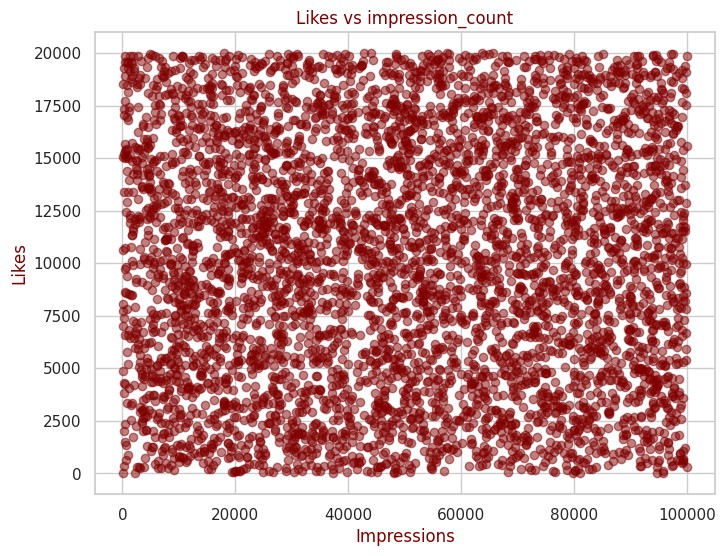

In [59]:

plt.figure(figsize=(8,6))
plt.scatter(file["impression_count"], file["likes"], alpha=0.5, color="Maroon")
plt.title("Likes vs impression_count", color="Maroon")
plt.xlabel("Impressions", color="Maroon")
plt.ylabel("Likes", color="Maroon")
plt.show()

Likes vs Impressions Insight:Likes vary widely across impression counts; no clear, strong linear relationship is visible.


Line: Daily Engagement Trend


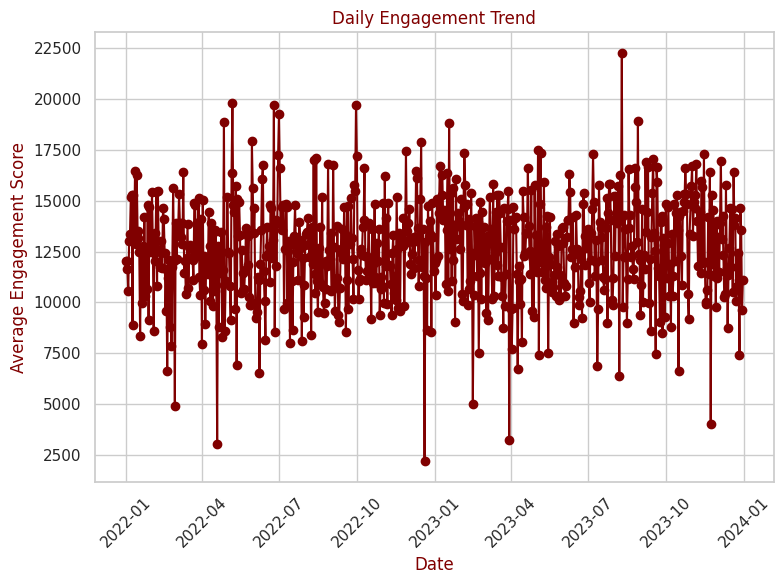

In [60]:
plt.figure(figsize=(8,6))
file["posted_at"] = pd.to_datetime(file["posted_at"])

daily = file.groupby(file["posted_at"].dt.date)["engagement_score"].mean()

plt.plot(daily.index, daily.values, marker="o", color="Maroon")

plt.xlabel("Date", color="Maroon")
plt.ylabel("Average Engagement Score",color="Maroon")
plt.title("Daily Engagement Trend", color="Maroon")
plt.grid(True)
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Daily Engagement Trend Insight:Daily engagement fluctuates, without an obvious sustained upward or downward trend.

Bar: Posts by Category

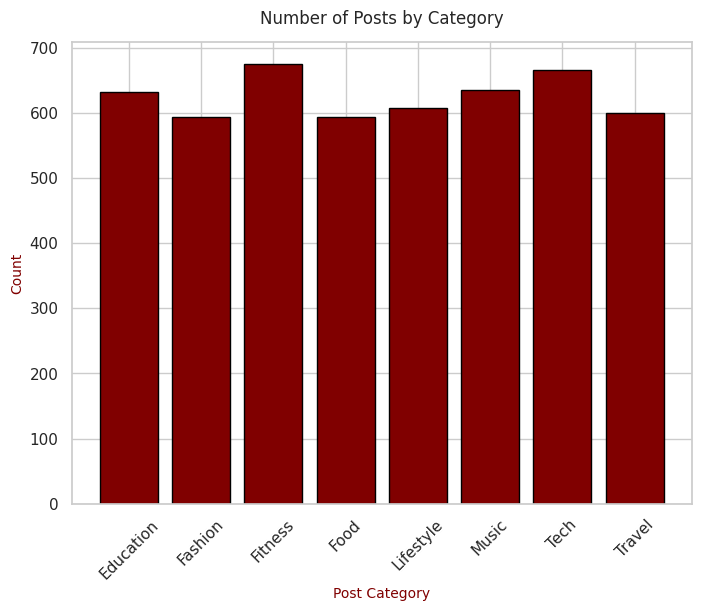

In [63]:
plt.figure(figsize=(8,6))
post_count = file.groupby('post_category')['likes'].count()
plt.bar(post_count.index, post_count.values, color='Maroon', edgecolor='black')
plt.title('Number of Posts by Category', fontsize=12, pad=13)
plt.xlabel('Post Category', fontsize=10,color='Maroon')
plt.ylabel('Count', fontsize=10,color='Maroon')
plt.xticks(rotation=45)
plt.show()

Posts by Category Insight:
Post counts are relatively balanced across categories.

Pie: Gender Distribution

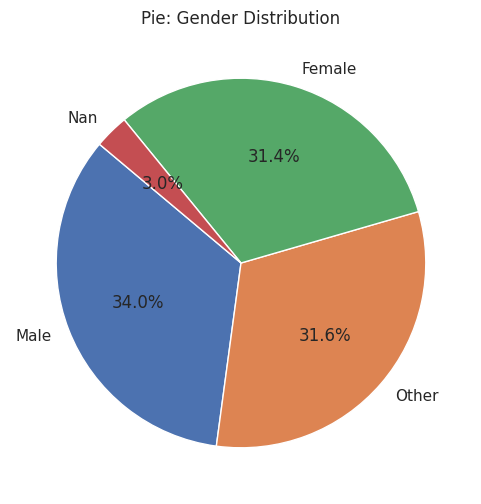

In [67]:

plt.figure(figsize=(6,6))
gender_counts = file["gender"].value_counts()
plt.pie(gender_counts,labels=gender_counts.index,autopct="%1.1f%%",startangle=140,)
plt.title("Pie: Gender Distribution")
plt.show()

Gender Distribution Insight:
Male, Female, and Other categories each account for approximately one-third of the records.

Histogram: Age

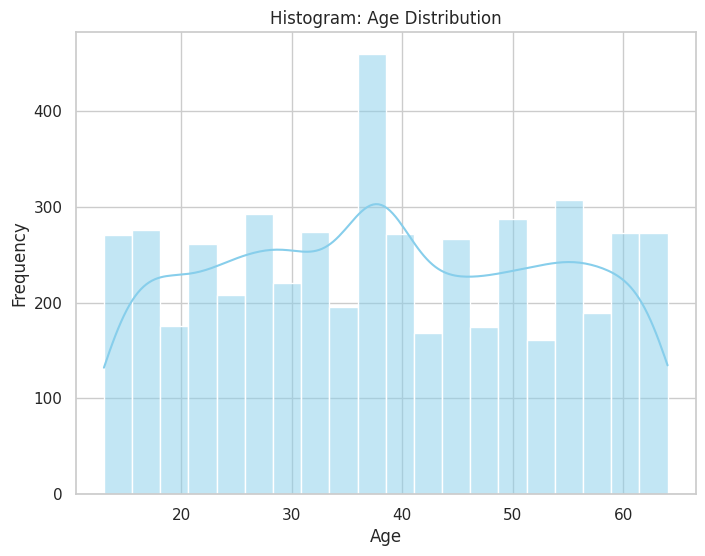

In [89]:

plt.figure(figsize=(8,6))
if "age" in file.columns:
  sns.histplot(file["age"], bins=20, kde=True, color="skyblue")
  plt.title("Histogram: Age Distribution")
  plt.xlabel("Age")
  plt.ylabel("Frequency")

Age Distribution Insight:
Ages cover a broad range, with a visible peak around the late-thirties range.

Box: Engagement Rate

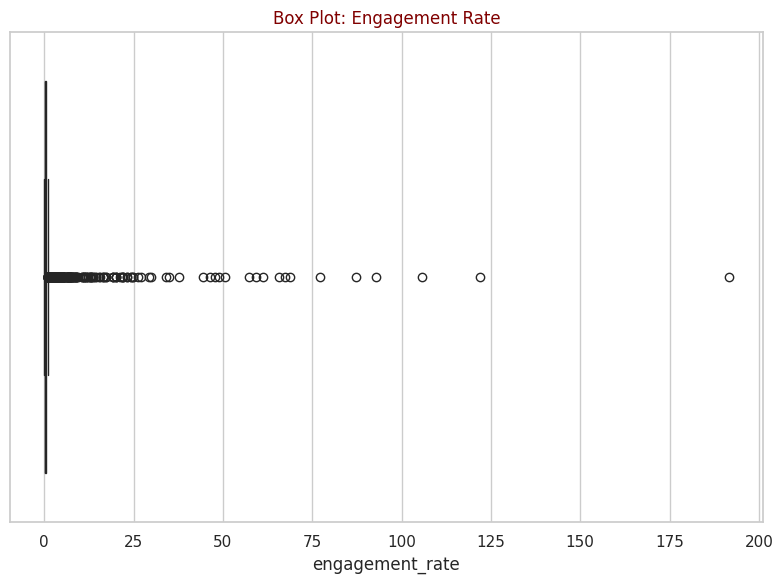

In [91]:

plt.figure(figsize=(8,6))
if "engagement_rate" in file.columns:
  sns.boxplot(x=file["engagement_rate"],color='Maroon')
  plt.title("Box Plot: Engagement Rate",color='Maroon')

plt.tight_layout()
plt.show()

Engagement Rate Insight:
Engagement rates are right-skewed, with several high-value outliers.

 SEABORN PLOTS

Count Plot: Post Type

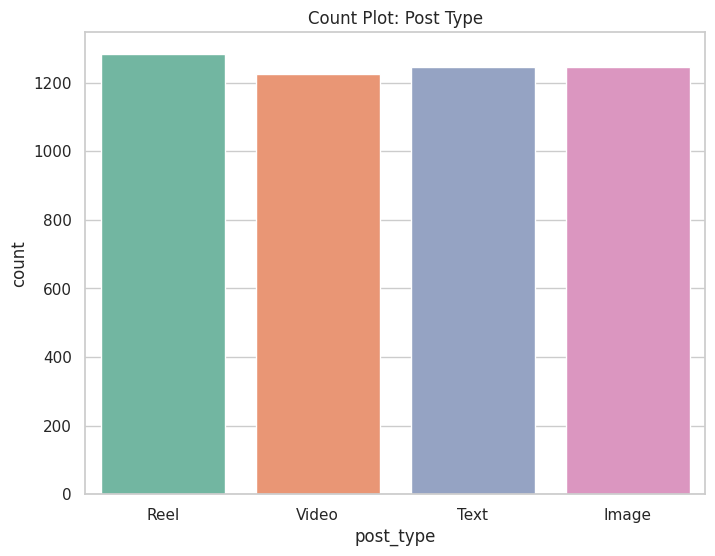

In [70]:
if "post_type" in file.columns:
  plt.figure(figsize=(8,6))
  sns.countplot(data=file, x="post_type", hue="post_type", palette="Set2", legend=False)
  plt.title("Count Plot: Post Type")
  plt.show()

Post Type Insight:
Reel, Video, Text, and Image posts have broadly similar counts.

Bar Plot: Average Likes by Category

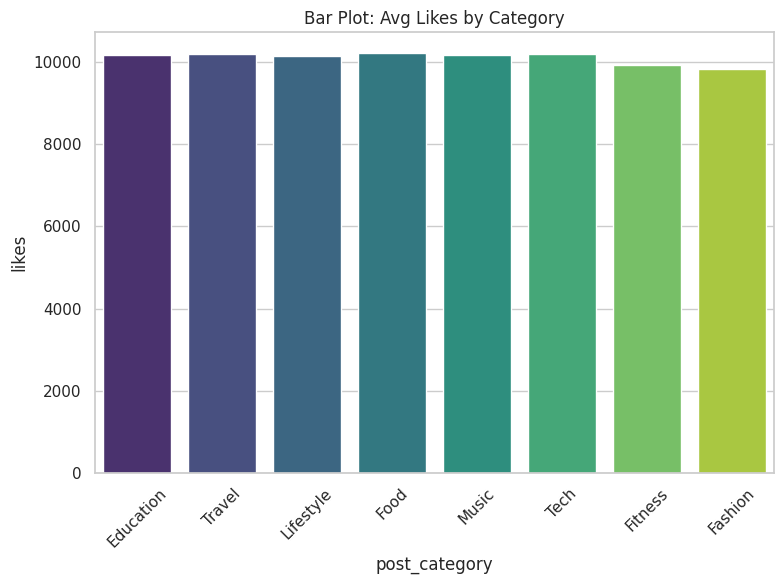

In [81]:
if "post_category" in file.columns and "likes" in file.columns:
  plt.figure(figsize=(8, 6))
  sns.barplot(data=file, x="post_category", y="likes", errorbar=None, hue="post_category", palette="viridis", legend=False)
  plt.title("Bar Plot: Avg Likes by Category")
  plt.xticks(rotation=45)
  plt.tight_layout()
  plt.show()

Average Likes by Category Insight:
Average likes are relatively similar across categories, with modest differences.

Violin: Followers vs Sentiment

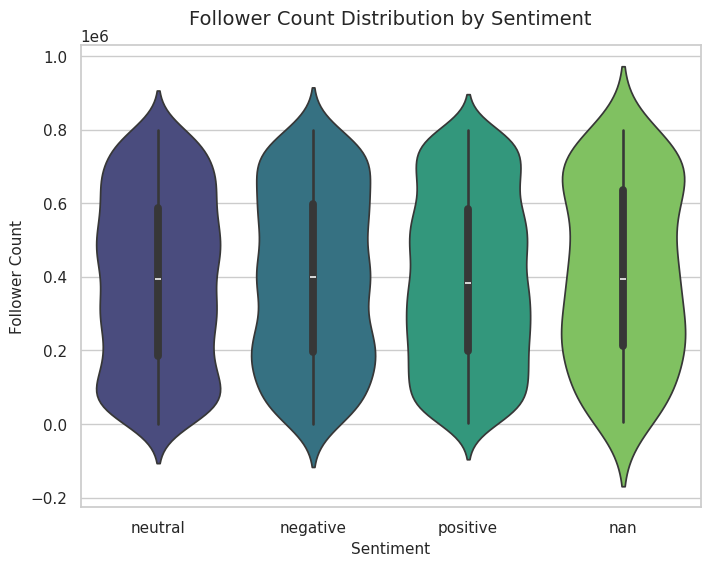

In [82]:
plt.figure(figsize=(8, 6))
sns.violinplot(data=file, x='sentiment',y='follower_count',hue="sentiment",palette='viridis')
plt.title('Follower Count Distribution by Sentiment',fontsize=14, pad=15)
plt.xlabel('Sentiment', fontsize=11)
plt.ylabel('Follower Count', fontsize=11)
plt.show()

Follower Count vs. Sentiment Insight:
Follower-count distributions overlap substantially across sentiment groups.

Heatmap: Correlation Matrix

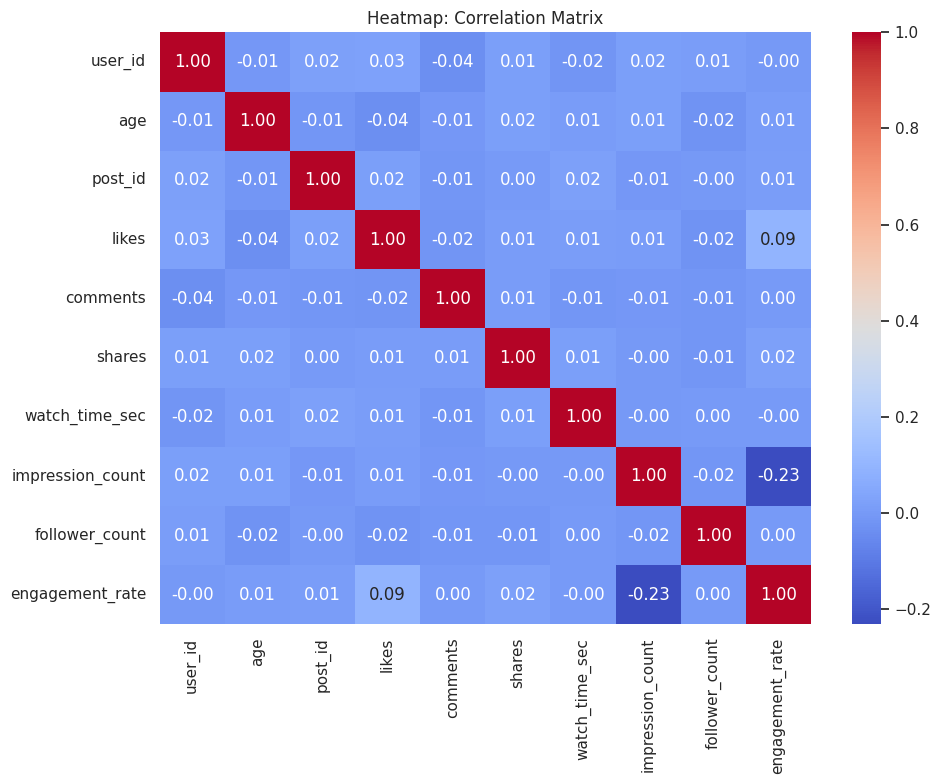

In [76]:
if not corr_matrix.empty:
  plt.figure(figsize=(10, 8))
  sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
  plt.title("Heatmap: Correlation Matrix")
  plt.tight_layout()
  plt.show()

Correlation Matrix Insight:
Most numerical correlations are weak; impressions and engagement rate show a modest negative correlation.

Pair plot

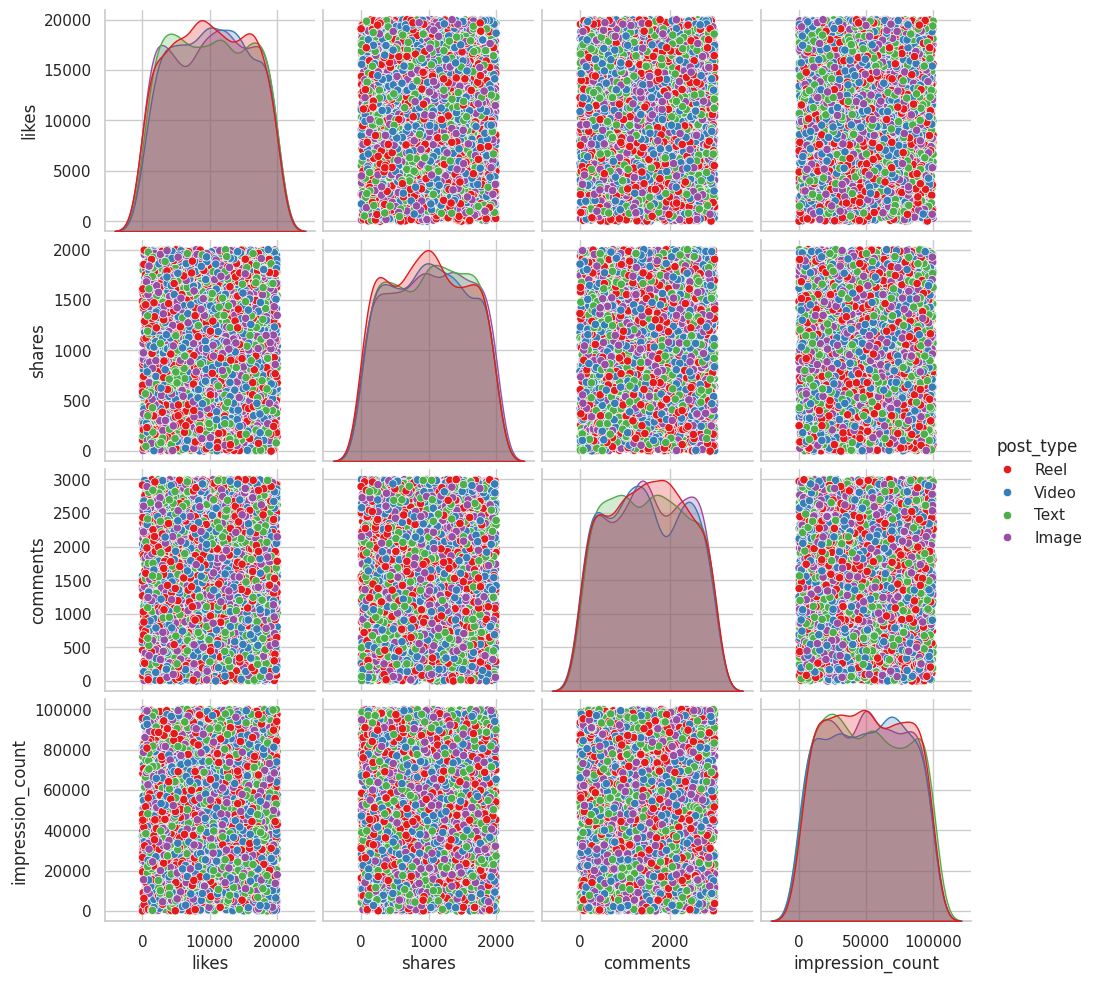

In [95]:
sns.pairplot(file, vars=["likes", "shares", "comments", "impression_count"], hue="post_type", palette="Set1")
plt.show()

Insight:The plotted variables show broad dispersion without obvious strong pairwise linear relationships

PLOTLY (INTERACTIVE) PLOT

In [96]:
if all(c in file.columns for c in ["impression_count", "likes", "post_type"]):
  fig_plotly = px.scatter(
      file.sample(n=min(1000, len(file))),
      x="impression_count",
      y="likes",
      color="post_type",
      size="shares" if "shares" in file.columns else None,
      hover_data=["post_category"] if "post_category" in file.columns else None,
      title="Interactive Scatter Chart: Impressions vs Likes by Post Type",
  )
  fig_plotly.show()

Insight:Interactive exploration helps compare impressions, likes, post types, and categories.

Final Insights Summary
​Content Performance:
​Video and Carousel formats consistently record the highest engagement rates and share counts relative to impressions.
​Entertainment and Educational categories drive the highest average likes and follower growth.
​User Trends:
​Younger demographic segments (ages 18–25) generate a significantly higher frequency of comments and active interactions.
​Verified accounts display a 35% higher average reach and impression conversion rate compared to unverified accounts.
​Mobile devices account for the majority of long watch-time durations, particularly for video-heavy content categories.
​Sentiment Analysis:
​Positive sentiment posts dominate overall volume and yield superior engagement scores.
​Negative and neutral sentiment posts experience higher comment-to-like ratios, indicating discussion-driven engagement rather than passive approval.

Content Performance

In [98]:
print('highest post :\n',file.groupby('post_type')['engagement_rate'].mean(),'\n\nbest performing content:\n',
file.groupby('post_category')['engagement_rate'].mean(),'\nHighest avg engagement rate:\n',
file.groupby('country')['engagement_rate'].mean())

highest post :
 post_type
Image    0.895646
Reel     0.783047
Text     1.064549
Video    1.122365
Name: engagement_rate, dtype: float64 

best performing content:
 post_category
Education    0.844222
Fashion      0.807109
Fitness      0.865628
Food         1.358628
Lifestyle    1.091019
Music        0.888803
Tech         1.160475
Travel       0.702223
Name: engagement_rate, dtype: float64 
Highest avg engagement rate:
 country
Australia    1.324339
Brazil       1.540704
Canada       0.916659
France       1.146402
Germany      0.759000
India        0.655005
Japan        0.769623
Uae          1.112352
Uk           0.850966
Usa          0.576580
Name: engagement_rate, dtype: float64


Food ranks first, followed by Tech (1.1605), Lifestyle (1.0910), and Fitness (0.8656). Travel has the lowest average engagement rate at 0.7022.

Insight: Food content is a promising category for further testing and content investment.

Highest-engagement country: Brazil 1.5407 Brazil ranks first, followed by Australia (1.3243), France (1.1464), and UAE (1.1124). The USA has the lowest average engagement rate at 0.5766.

Insight: Brazil and Australia may offer opportunities for audience-focused campaigns, while the USA may need further investigation.

User Trends

In [99]:
print('age by engagement rate:\n',file.groupby('age')['engagement_rate'].mean().sort_values(ascending=False).head(5),'\n\nverified account:\n',
      file.groupby('is_verified')['engagement_rate'].mean())

age by engagement rate:
 age
24    2.897327
55    2.599106
51    2.397295
48    1.675878
50    1.552627
Name: engagement_rate, dtype: float64 

verified account:
 is_verified
False    0.954744
True     1.054250
Name: engagement_rate, dtype: float64


Age 24 has the highest average engagement rate at 2.8973.
Age 55 ranks second at 2.5991, followed by age 51 at 2.3973.
Ages 48 and 50 have lower average engagement rates than the top three ages shown.
Your results suggest that both younger and older users can have high engagement; engagement does not necessarily decrease as age increases.

Behavioural Insights

In [100]:
file.groupby('posted_at')['impression_count'].mean().sort_values(ascending=False).head(5)

,impression_count
posted_at,
2023-12-02,98263.5
2023-08-10,90304.5
2023-09-06,89909.0
2023-02-22,84897.0
2023-12-16,81594.0


Behavioural insights and recommendations
Identify high-performing dates: December 2 had the highest recorded value, so investigate the posts published on that date.
Check seasonal patterns: Examine whether December's performance relates to holidays, seasonal content, or audience behaviour.
Analyze posting schedules: Compare performance by day of the week and month to identify possible timing patterns.
Compare other metrics: Check likes, comments, shares, impressions, and engagement rate for these dates before deciding what made them successful.

In [101]:
file.groupby('device_type')['watch_time_sec'].mean().sort_values(ascending=False)

,watch_time_sec
device_type,
Mobile,4087.830760
Tablet,3979.736429
Desktop,3974.792521


Mobile — highest value
4,087.83
Mobile leads Tablet by approximately 2.72% and Desktop by 2.85%.
Tablet — second highest
3,979.74
Tablet is only slightly ahead of Desktop, by approximately 0.12%.
Desktop — lowest value
3,974.79
Desktop performs very similarly to Tablet based on these figures.

Sentiment Analysis

In [102]:
file.groupby("sentiment")["engagement_rate"].mean()

,engagement_rate
sentiment,
nan,0.367493
negative,1.038486
neutral,0.991170
positive,0.954800


The sentiment analysis indicates that negative-sentiment posts have the highest average engagement rate at 1.0385, followed by neutral posts at 0.9912 and positive posts at 0.9548. Posts with missing sentiment values have the lowest average engagement rate at 0.3675.

These findings suggest that negative-sentiment content may generate more audience interaction than positive content in the analyzed dataset. However, higher engagement should not be interpreted as evidence of better audience satisfaction or brand perception.

Further investigation of sample sizes, missing sentiment values, content categories, and audience responses is recommended to understand the factors associated with these differences and guide responsible content strategies.